# Classes, Objects, self & Encapsulation

**OOP class 1 + 2 notes (merged).** The foundation of Object-Oriented Python:
what a class really is, how objects are created, why `self` is needed, `__init__`
constructors, `@dataclass`, and the first pillar — **encapsulation** with getters/setters
and public/protected/private access modifiers.

**What you will learn**
- Class as blueprint vs object as instance
- Why hard-coded attribute values fail, and how `__init__(self, ...)` fixes it
- What `self` points to and how `Person.walk(p1)` equals `p1.walk()`
- `@dataclass` for automatic constructors
- Encapsulation: control access with getters/setters
- Access modifiers: public, protected (`_name`), private (`__name`)

## Warm-up — file handling revision

The class started by writing revision notes into `test.txt` with `with open(..., 'w+')`
(file handling from the previous class).

In [ ]:
# warm-up: writing multi-line notes into a file with w+ (read+write) mode
with open('test.txt', 'w+') as f:
    f.write('''Law of Large Numbers
Law of large numbers states that if the same experiment or study is repeated independently for large number of times, then the average of the results of the trials must be 
close to the expected value''')
    f.seek(0)
    print(f.read())

In [ ]:
with open('test.txt','r+' ) as f:
    print(f.read())
    f.write('''Hypothesis Testing
                • Hypothesis testing is a statistical tool which is use to confirm our observation or assumption or hypothesis about population using sample data.
                • First we study the sample of data and we assume that observation on sample is also followed by population. 
                • So, using Hypothesis testing, we can determine whether we have enough statistical evidence to conclude if the hypothesis about population is true or not.
                There are two hypothesis statements:
                Null Hypothesis (H0) :
                • It states that there is no significant difference between sample and population variables.
                • It treats as everything is same or equal.''')
    f.seek(0)
    print(f.read())


## Why Object-Oriented Programming?

- **Uniformity** • **Reduce** complexity • **Reusability** • easier **Debugging** • **Code management**
- OOP models a program as **objects** that bundle data (attributes) and behaviour (methods)
  instead of loose variables and functions.

## Class — a blueprint, template or model

- A class describes *what* an object holds and *what it can do* — objects are built from it.
- Syntax:
  ```python
  class Person:
      name = "Arham"          # attributes
      def walk(self):         # behaviour (method)
          print("Object is walking")
  ```
- `p1 = Person()` creates an **object (instance)** of the blueprint.

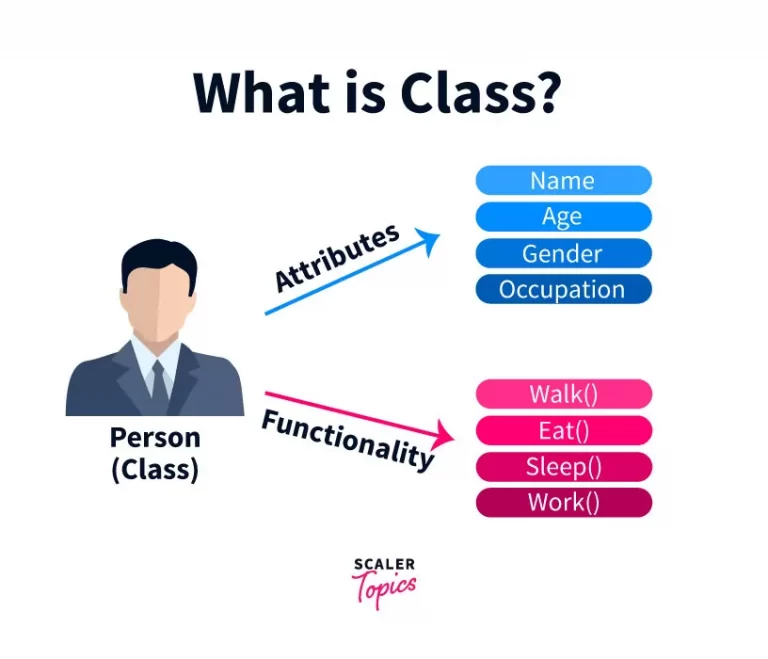

In [ ]:
# class attributes are shared — every object of this Person class gets the SAME values
class Person:
    # attributes / properties / chracteristics 
    name  = "Arham"
    age = 10
    gender = 'Male'
    occupation = 'Student'

    def walk(self):
        print("Object is walking")
    def eat(self):
        print("Object is eating")
    def sleep(self):
        print("Object is sleeping")
    def work(self):
        print("Object is working")
# Note: All objects will have same name and other properites because values assigned are fixed.

In [ ]:
# p1 = Person() builds the first object (instance) from the blueprint
p1 = Person()

In [ ]:
p2 = Person()

In [ ]:
p2

In [ ]:
p1

In [ ]:
p1.name

In [ ]:
p2.occupation

In [ ]:
p1.walk()

In [ ]:
Person.walk(p1)

> `Person.walk(p1)` is the *unbound* form of `p1.walk()` — Python needs the object
> so it can fill the `self` parameter.

In [ ]:
# constructor runs at creation time — but with hard-coded values (fixed next section)
class Student:
    def __init__(self):        
        self.name = 'Arham'
        self.roll = 123
        self.course = 'Python'
        self.age  = 12

    def take_class(self):
        print(f"{self.name} is taking class")
# self tells WHICH object is calling the method, so the correct object property is used

In [ ]:
s1 = Student()

In [ ]:
s2 = Student()

In [ ]:
s1.take_class()

In [ ]:
s2.take_class()

> ⚠️ **The wrong way:** `__init__` here assigns the *same fixed values* to every
> object — `s1` and `s2` start identical, so changing `s2.name` later is clumsy.
> The next section passes real arguments to `__init__` instead.

In [ ]:
s2.name = 'Usman'
s2.roll = 456
s2.course = 'ML'
s2.age = 23

# this changed the 2nd object property to a value copied from the 1st object — which is wrong

In [ ]:
s2.take_class()

In [ ]:
s1.take_class()

In [ ]:
# right way: constructor arguments give every object its OWN distinct values
# the right way is the constructor below, so every object gets its own distinct values
class Student:
    def __init__(self, name, roll, course, age):        
        self.name = name
        self.roll = roll
        self.course = course
        self.age  = age

    def take_class(self):
        print(f"{self.name} is taking class")
    def profile(self):
        print(f"Name: {self.name}")
        print(f"Roll: {self.roll}")
        print(f"Course: {self.course}")
        print(f"Age: {self.age}")

In [ ]:
s1 = Student('Arham', 123, 'Python', 10)

In [ ]:
s2 = Student('Usman', 124, 'ML', 19)

In [ ]:
s3 = Student('Furqan', 125, 'Python', 19)

In [ ]:
s1.profile()

In [ ]:
s2.profile()

In [ ]:
s3.profile()

In [ ]:
# practice: build each class yourself using the pattern above
# practice: build a Person class

In [ ]:
# practice: build a Laptop class
class Laptop:    
    def __init__(self, brand, processor, generation, ram, storage):
        self.brand = brand
        self.processor = processor
        self.generation = generation
        self.ram = ram
        self.storage =storage    
    
    def show_configuration(self):
        return f"""
        Brand     : {self.brand}
        Processor : {self.processor}
        Generation: {self.generation}
        Ram       : {self.ram}
        Storage   : {self.storage}        
        """
    def run_code(self):
        return "Code is working fine!"
        

In [ ]:
lap1 = Laptop('Hp','Corei7', '10th', '16Gb', '1Tb')

In [ ]:
print(lap1.show_configuration())

In [ ]:
print(lap1.run_code())

In [ ]:
# practice: build a Car class

In [ ]:
#  Dog class banaen

## @dataclass — skip the repetitive constructor

- `@dataclass` (from `dataclasses`) auto-generates `__init__` from the type-annotated fields:
  `@dataclass class Patient: name: str; age: int` → `Patient("arham", 12)` just works.
- Great for data-only classes where you would otherwise type the same `self.x = x` lines.

In [ ]:
# dataclasses module provides @dataclass so __init__ writes itself
from dataclasses import dataclass

In [ ]:
@dataclass
class Patient:
    name:str
    age:int
    disease:str
    

In [ ]:
p1 = Patient('arham', "12", 'KhataBohatHy')

## The 4 pillars of OOP

1. **Encapsulation** → hide & control access to the data (this class)
2. **Inheritance** → child reuses parent's code
3. **Polymorphism** → same method name, different behaviour
4. **Abstraction** → show only the essential details

## Encapsulation — control how data is read & changed

- Bundle the data **and** the methods that manage it inside one class.
- Directly changing `p1.age = 1200` is dangerous — a **setter** can validate first
  (`if age > 0:`), a **getter** controls how the value is returned.

In [ ]:
p1.name

In [ ]:
p1.age = 1200

In [ ]:
p1.age

In [ ]:
# private attribute (__ram) + public getter/setter = encapsulation in action
class Laptop:    
    def __init__(self, brand, processor, generation, ram, storage):
        self.brand = brand
        self.processor = processor
        self.generation = generation
        self.ram = ram
        self.storage =storage    
    
    def show_configuration(self):
        return f"""
        Brand     : {self.brand}
        Processor : {self.processor}
        Generation: {self.generation}
        Ram       : {self.ram}
        Storage   : {self.storage}        
        """
    def run_code(self):
        return "Code is working fine!"

    def get_ram(self):
        return self.ram
    def set_ram(self, new_ram):
        self.ram = new_ram
        

In [ ]:
lap1 = Laptop('Hp','Corei7', '10th', '16Gb', '1Tb')

In [ ]:
lap1.get_ram()

In [ ]:
lap1.set_ram('64Gb')

In [ ]:
lap1.get_ram()

## Access modifiers — who may touch this member?

Three levels control (by convention) how far a variable/method can be reached:
1. **Public** — accessible from anywhere
2. **Protected** (`_name`) — meant for the class & its subclasses
3. **Private** (`__name`) — only inside the class (name-mangled)

### 1. Public access modifier

- Members declared public can be accessed from **anywhere** in the program.
- In Python every name without a leading underscore is public by default.

### 2. Protected access modifier

- A member is protected when its name starts with a **single underscore** (`_name`).
- Convention: only the class and its subclasses should use it — but Python does **not**
  enforce anything; the value is still readable from outside.

In [ ]:
# single underscore prefix marks the attribute as protected by convention
class Student:
    def __init__(self, name, roll, branch):
        self._name = name            # all protected
        self._roll = roll           
        self._branch = branch       

In [ ]:
# In class we imported from a separate laptop.py module (not part of this repo).
# The Laptop class defined in the Encapsulation section above is equivalent.
# from laptop import Laptop

In [ ]:
lap1 = Laptop('hp','COREI5', '5TH', 8, 256)

---

## Appendix: public, protected & private (access modifiers)

## Public vs Protected vs Private in Python

- Strongly typed languages *enforce* these restrictions; Python only **follows conventions**
  — nothing truly stops you from touching a "protected" or "private" value.
- Below: a `Car` class demonstrating all three levels, a `Suzuki(Car)` subclass, and the
  errors you get when you break the rules.

Public private and protected functionalities are highly restricted (strongly typed) in most of the typed languages 
But in python you will not be restricted to access public private and protected variables, they can be overridden. 

In [ ]:
# everything without an underscore is public — accessible and modifiable anywhere
# default
# All instance variables are public by default 
class Car():
    # public class variable can be accessed from any where 
    wheels = 4
    def __init__(self,windows, doors, enginetype):
        
        # accessed
        self.windows =windows
        self.doors =doors
        self.enginetype =enginetype

In [ ]:
audi = Car(4,5,"Diesel")

# accessible
# variables
dir(audi)

In [ ]:
# Suzuki inherits from Car: super().__init__() reuses the parent constructor
class Suzuki(Car):
    def __init__(self,windows,doors,enginetype, hp):
        super().__init__(windows,doors,enginetype)
        self.hp = hp
suz = Suzuki(4,4,"Petrol","1600")

# you will notice public variables are all accessible to child class also
dir(suz)

#### Proof of concept

In [ ]:
# proof: public values can be READ and MODIFIED from outside the class
#public variable can be accessed 

print(audi.windows)

# public variable can be modified 
audi.windows= 6
# accessing modified value
print(audi.windows)

In [ ]:
# underscore-prefixed attributes = protected (a warning, not a lock)
# to make a variable protected use a single underscore before a variable name like _name = "Asad"
class Car():
    def __init__(self,windows, doors, enginetype):
        
        # accessed
        #a sub class only by definition but python has no restriction 
        #it can also be accessed from any where
        # but python dont restrict actually
        self._windows =windows
        self._doors =doors
        self._enginetype =enginetype
        self.hello = "heooooooo"
        self.pappooo = "Papooooo"
        

audi = Car(4,5,"Diesel")
dir(audi)

class Suzuki(Car):
    def __init__(self,windows,doors,enginetype, hp):
        super().__init__(windows,doors,enginetype)
        self.hp = hp
suz = Suzuki(4,4,"Petrol","1600")

In [ ]:
audi.pappooo

In [ ]:
dir(suz)

In [ ]:
audi._windows = 10

In [ ]:
audi._windows

In [ ]:
# protected values are STILL readable from outside — _name is only a convention
suz._windows

In [ ]:
# double underscore = private: Python renames it to _Car__windows behind the scenes
class Car():
    def __init__(self,windows, doors, enginetype):
        
        # accessed
        self.__windows =windows
        self.__doors =doors
        self.__enginetype =enginetype
#         self.name = "Nasir"
audi = Car(4,5,"Diesel")

In [ ]:
audi.__windows

> ⚠️ Expected error: `self.__windows` is private → name-mangled to
> `_Car__windows`, so `audi.__windows` raises `AttributeError`.
> (Reading `audi._Car__windows` would work, but that breaks the whole point of private.)

In [ ]:
# protected _m1 with explicit getter/setter methods (the controlled way)
class Student:
    school = "SSUET"
    def __init__(self):
        self._m1 = 'Python'
        self._m2 = 'Java'
        self._m3 = 'MachineLearning'
    def avg(self):
        return (self._m1+self._m2+self._m3)/3
    
    def information(self):
        return self.school
    
    def getm1(self):
        return self._m1
    
    def setm1(self,newm1):
        self._m1=newm1
    

In [ ]:
s1 =Student()

In [ ]:
s1.setm1('Stats')

In [ ]:
s1.getm1()

In [ ]:
# private __m1: only the class methods can safely read/write it
class Student:
    school = "SSUET"
    def __init__(self):
        self.__m1 = 'Python'
        self.__m2 = 'Java'
        self.__m3 = 'MachineLearning'
    def avg(self):
        return (self.__m1+self.__m2+self.__m3)/3
    
    def information(self):
        return self.school
    
    def getm1(self):
        return self.__m1
    
    def setm1(self,newm1):
        self.__m1=newm1
    

In [ ]:
s2 =Student()

In [ ]:
s2.getm1()

In [ ]:
s2.__m1

## 🔑 Key Takeaways / Quick Revision

- **Class** = blueprint/template • **Object** = an instance built from it: `p1 = Person()`.
- Attributes defined in the class body are **shared by all objects** — pass values through
  the constructor instead: `def __init__(self, name, roll): self.name = name`.
- `self` = reference to the *current object*; Python passes it automatically when you call `obj.method()`.
- `Person.walk(p1)` is the unwritten form of `p1.walk()` — both pass `p1` as `self`.
- `@dataclass class Patient: name: str` auto-generates `__init__` and `__repr__`.
- **Encapsulation** = bundle data + the methods that control it → getters read, setters validate.
- Access modifiers (naming conventions, not hard rules in Python):
  - `name` → **public**, accessible anywhere
  - `_name` → **protected**, meant for the class & subclasses (still accessible)
  - `__name` → **private**, name-mangled to `_ClassName__name` → direct access raises `AttributeError`